## Time-Series Fundamentals and Stationarity

### Learning Goals
* Understand what distinguishes time-series data from cross-sectional data (temporal ordering, lag dependence).
* Define **weak stationarity** (constant mean, constant variance, autocovariance dependent only on time lag).
* Recognize the dangers of non-stationarity (spurious regressions and trending series).

---

### 1. What Makes Time-Series Data Different?

Time-series observations are ordered sequentially. Current values frequently depend on past realizations, seasonal cycles, or long-term trends.

* **Stationary Series:** Fluctuates around a constant long-run mean with constant variance and temporary memory.
* **Non-Stationary Series (e.g., Random Walk):** Accumulates shocks permanently, exhibiting trends and unstable variances.

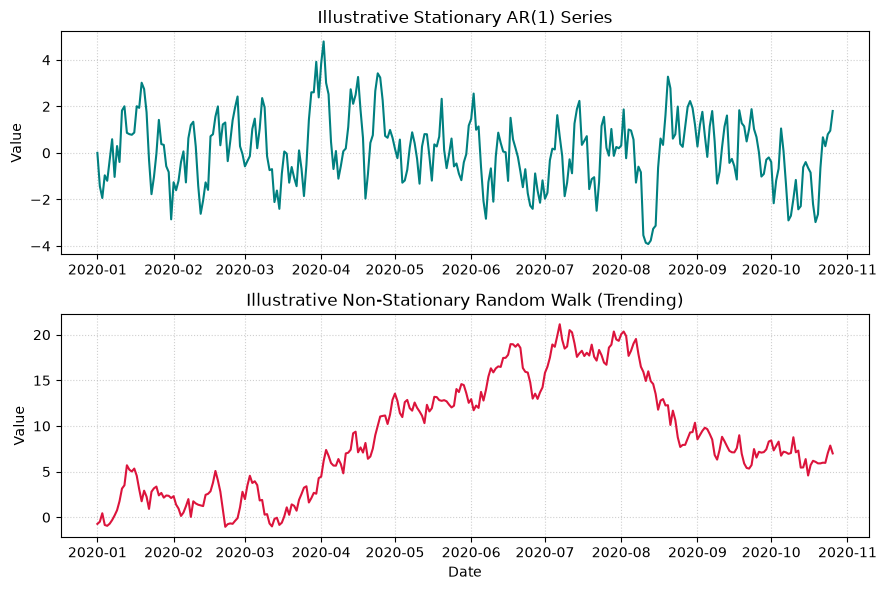

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(15)
dates = pd.date_range("2020-01-01", periods=300, freq="D")

# Generate stationary AR(1) series
stationary = np.zeros(300)
for t in range(1, 300):
    stationary[t] = 0.7 * stationary[t-1] + rng.normal()

# Generate non-stationary random walk (trending) series
trending = np.cumsum(rng.normal(0, 1, 300))

fig, axes = plt.subplots(2, 1, figsize=(9, 6))

axes[0].plot(dates, stationary, color='teal', linewidth=1.5)
axes[0].set_title("Illustrative Stationary AR(1) Series")
axes[0].set_ylabel("Value")
axes[0].grid(linestyle=':', alpha=0.6)

axes[1].plot(dates, trending, color='crimson', linewidth=1.5)
axes[1].set_title("Illustrative Non-Stationary Random Walk (Trending)")
axes[1].set_ylabel("Value")
axes[1].set_xlabel("Date")
axes[1].grid(linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 2. Why Stationarity Matters

Many time-series modeling techniques (such as ARMA/ARIMA) require the underlying process to be stationary. Regressing two independent non-stationary series on one another can produce a **spurious regression**—yielding high $R^2$ values and significant $t$-statistics even when no true economic relationship exists.

---

### Exercises

Try each problem before running the verification code below:

1. Compare the visual behavior of the stationary AR(1) plot versus the random walk plot.
2. Explain why time order must be strictly preserved in time-series analysis (unlike cross-sectional data).
3. Why can two completely unrelated trending series appear strongly correlated in a standard OLS regression?

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

print("\n1. Visual Comparison:")
print("   - The stationary series reverts continuously to its mean (zero), whereas")
print("     the random walk drifts away indefinitely without a fixed long-run mean.")

print("\n2. Why Time Order Matters:")
print("   - Preserving time order is essential because observations depend on past lags;")
print("     shuffling data destroys temporal dependence structures and invalidates forecasting.")

print("\n3. Spurious Regression of Trending Series:")
print("   - Both series share a common trend over time, which drives correlation independently")
print("     of any true causal mechanism, resulting in false statistical significance.")

=== Exercise Solutions & Checks ===

1. Visual Comparison:
   - The stationary series reverts continuously to its mean (zero), whereas
     the random walk drifts away indefinitely without a fixed long-run mean.

2. Why Time Order Matters:
   - Preserving time order is essential because observations depend on past lags;
     shuffling data destroys temporal dependence structures and invalidates forecasting.

3. Spurious Regression of Trending Series:
   - Both series share a common trend over time, which drives correlation independently
     of any true causal mechanism, resulting in false statistical significance.
